<a href="https://colab.research.google.com/github/PalQuisp/Sis420-int/blob/main/Ejercicio_2_segundo_parciaL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture

# Hace que los resultados aleatorios sean reproducibles.
np.random.seed(42)

In [2]:
NUM_TABLONES = 7
PESO_AGENTE = 55  # peso que soporta el agente, en unidades simuladas

# Resistencia real de cada tablón: el agente no la conoce.
resistencia_real = np.random.randint(35, 91, size=NUM_TABLONES)

# Señales observables. En general, menor resistencia implica señales más altas.
vibracion = np.clip((95 - resistencia_real) / 60 + np.random.normal(0, 0.10, NUM_TABLONES), 0, 1)
deformacion = np.clip((95 - resistencia_real) / 65 + np.random.normal(0, 0.10, NUM_TABLONES), 0, 1)
corrosion = np.clip((95 - resistencia_real) / 70 + np.random.normal(0, 0.12, NUM_TABLONES), 0, 1)

datos = pd.DataFrame({
    "Tablon": np.arange(1, NUM_TABLONES + 1),
    "Vibracion": vibracion,
    "Deformacion": deformacion,
    "Corrosion": corrosion
})

datos

,Tablon,Vibracion,Deformacion,Corrosion
0,1,0.343251,0.291889,0.205323
1,2,0.126586,0.162658,0.000000
2,3,0.691255,0.300980,0.633021
3,4,0.843410,0.535201,0.630050
4,5,0.253053,0.220694,0.265246
5,6,0.937589,0.714102,0.586173
6,7,0.620325,0.646809,0.506103


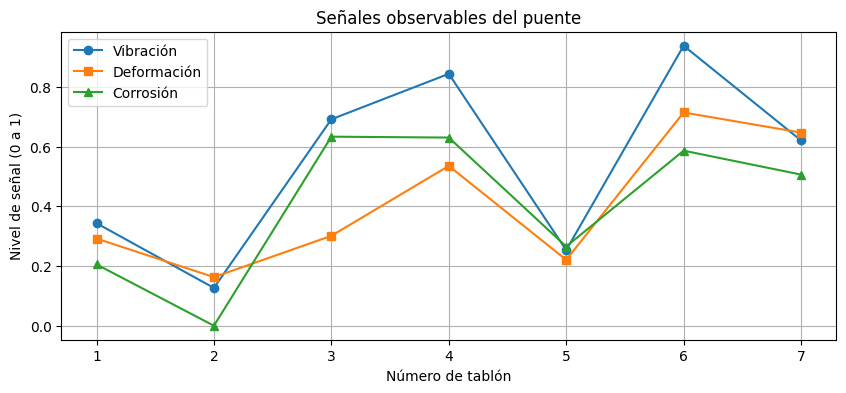

In [3]:
plt.figure(figsize=(10, 4))
plt.plot(datos["Tablon"], datos["Vibracion"], marker="o", label="Vibración")
plt.plot(datos["Tablon"], datos["Deformacion"], marker="s", label="Deformación")
plt.plot(datos["Tablon"], datos["Corrosion"], marker="^", label="Corrosión")
plt.xticks(range(1, NUM_TABLONES + 1))
plt.xlabel("Número de tablón")
plt.ylabel("Nivel de señal (0 a 1)")
plt.title("Señales observables del puente")
plt.grid(True)
plt.legend()
plt.show()

In [4]:
caracteristicas = datos[["Vibracion", "Deformacion", "Corrosion"]]

escalador = StandardScaler()
X_escalado = escalador.fit_transform(caracteristicas)

print("Matriz de datos:", X_escalado.shape)
print(X_escalado)

Matriz de datos: (7, 3)
[[-0.70646838 -0.58487299 -0.86391805]
 [-1.46491775 -1.22300797 -1.75807411]
 [ 0.51173873 -0.53998158  0.99865449]
 [ 1.04436859  0.61658888  0.98571611]
 [-1.02221477 -0.93642645 -0.60295882]
 [ 1.37404872  1.49999264  0.79463871]
 [ 0.26344485  1.16770747  0.44594167]]


In [5]:
k = 2
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
grupos = kmeans.fit_predict(X_escalado)

datos["Grupo_KMeans"] = grupos
datos

,Tablon,Vibracion,Deformacion,Corrosion,Grupo_KMeans
0,1,0.343251,0.291889,0.205323,1
1,2,0.126586,0.162658,0.000000,1
2,3,0.691255,0.300980,0.633021,0
3,4,0.843410,0.535201,0.630050,0
4,5,0.253053,0.220694,0.265246,1
5,6,0.937589,0.714102,0.586173,0
6,7,0.620325,0.646809,0.506103,0


In [6]:
promedios = datos.groupby("Grupo_KMeans")[["Vibracion", "Deformacion", "Corrosion"]].mean()
promedios

,Vibracion,Deformacion,Corrosion
Grupo_KMeans,,,
0,0.773145,0.549273,0.588837
1,0.240963,0.225080,0.156856


In [7]:
promedios["Indice_Riesgo"] = promedios.mean(axis=1)
promedios

,Vibracion,Deformacion,Corrosion,Indice_Riesgo
Grupo_KMeans,,,,
0,0.773145,0.549273,0.588837,0.637085
1,0.240963,0.225080,0.156856,0.207633


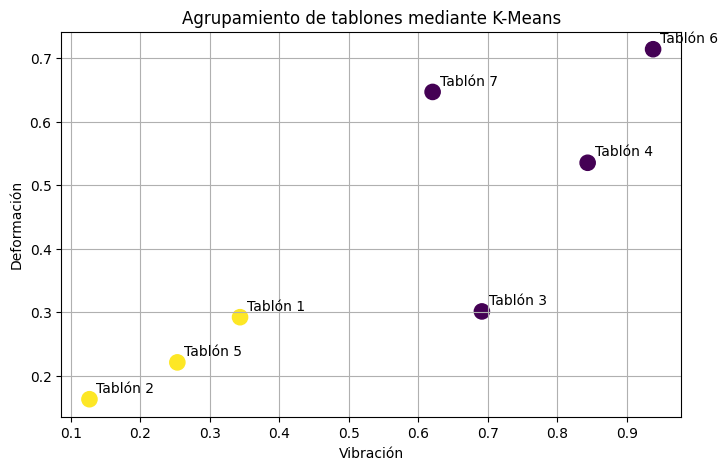

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(datos["Vibracion"], datos["Deformacion"],
            c=datos["Grupo_KMeans"], s=120, cmap="viridis")

for _, fila in datos.iterrows():
    plt.annotate(f"Tablón {int(fila['Tablon'])}",
                 (fila["Vibracion"], fila["Deformacion"]),
                 xytext=(5, 5), textcoords="offset points")

plt.xlabel("Vibración")
plt.ylabel("Deformación")
plt.title("Agrupamiento de tablones mediante K-Means")
plt.grid(True)
plt.show()

In [9]:
dbscan = DBSCAN(eps=1.2, min_samples=2)
etiquetas_dbscan = dbscan.fit_predict(X_escalado)

datos["Grupo_DBSCAN"] = etiquetas_dbscan
datos[["Tablon", "Grupo_DBSCAN"]]

,Tablon,Grupo_DBSCAN
0,1,0
1,2,-1
2,3,-1
3,4,1
4,5,0
5,6,1
6,7,1


In [10]:
gmm = GaussianMixture(n_components=2, n_init=5, random_state=42)
gmm.fit(X_escalado)

grupos_gmm = gmm.predict(X_escalado)
probabilidades = gmm.predict_proba(X_escalado)

datos["Grupo_GMM"] = grupos_gmm
datos

,Tablon,Vibracion,Deformacion,Corrosion,Grupo_KMeans,Grupo_DBSCAN,Grupo_GMM
0,1,0.343251,0.291889,0.205323,1,0,1
1,2,0.126586,0.162658,0.000000,1,-1,1
2,3,0.691255,0.300980,0.633021,0,-1,0
3,4,0.843410,0.535201,0.630050,0,1,0
4,5,0.253053,0.220694,0.265246,1,0,1
5,6,0.937589,0.714102,0.586173,0,1,0
6,7,0.620325,0.646809,0.506103,0,1,0


In [11]:
print("Probabilidades de pertenencia a cada grupo:")
print(np.round(probabilidades, 3))

Probabilidades de pertenencia a cada grupo:
[[0. 1.]
 [0. 1.]
 [1. 0.]
 [1. 0.]
 [0. 1.]
 [1. 0.]
 [1. 0.]]


In [12]:
# Asociamos a cada grupo su índice estimado de riesgo.
riesgo_por_grupo = promedios["Indice_Riesgo"].to_dict()

# Cada tablón hereda el riesgo estimado de su grupo.
datos["Riesgo_Estimado"] = datos["Grupo_KMeans"].map(riesgo_por_grupo)

# Regla de decisión ilustrativa: no pisar si el índice supera este umbral.
UMBRAL_RIESGO = 0.65

print("Peso del agente:", PESO_AGENTE)
print("Umbral de riesgo:", UMBRAL_RIESGO)

cruzo = True

for i in range(NUM_TABLONES):
    numero = i + 1
    riesgo = datos.loc[i, "Riesgo_Estimado"]

    print(f"\nAgente frente al tablón {numero}")
    print(f"Riesgo estimado: {riesgo:.3f}")

    if riesgo > UMBRAL_RIESGO:
        print("DECISIÓN: evitar el tablón. El agente se detiene.")
        cruzo = False
        break

    print("DECISIÓN: pisar el tablón.")

    # Esta comparación la realiza el simulador, no el agente.
    if resistencia_real[i] < PESO_AGENTE:
        print("¡CRAC! El tablón se rompe. El puente colapsa.")
        cruzo = False
        break
    else:
        print("El tablón soporta el peso. Continúa.")

if cruzo:
    print("\n¡ÉXITO! El agente cruzó los siete tablones.")
else:
    print("\nEl agente no logró completar el cruce.")

Peso del agente: 55
Umbral de riesgo: 0.65

Agente frente al tablón 1
Riesgo estimado: 0.208
DECISIÓN: pisar el tablón.
El tablón soporta el peso. Continúa.

Agente frente al tablón 2
Riesgo estimado: 0.208
DECISIÓN: pisar el tablón.
El tablón soporta el peso. Continúa.

Agente frente al tablón 3
Riesgo estimado: 0.637
DECISIÓN: pisar el tablón.
El tablón soporta el peso. Continúa.

Agente frente al tablón 4
Riesgo estimado: 0.637
DECISIÓN: pisar el tablón.
¡CRAC! El tablón se rompe. El puente colapsa.

El agente no logró completar el cruce.


In [ ]:
resultado = datos[["Tablon", "Riesgo_Estimado", "Grupo_KMeans"]].copy()
resultado["Resistencia_Real"] = resistencia_real
resultado["Soporta_Peso"] = resistencia_real >= PESO_AGENTE
resultado

,Tablon,Riesgo_Estimado,Grupo_KMeans,Resistencia_Real,Soporta_Peso
0,1,0.207633,1,73,True
1,2,0.207633,1,86,True
2,3,0.637085,0,63,True
3,4,0.637085,0,49,False
4,5,0.207633,1,77,True
5,6,0.637085,0,42,False
6,7,0.637085,0,55,True


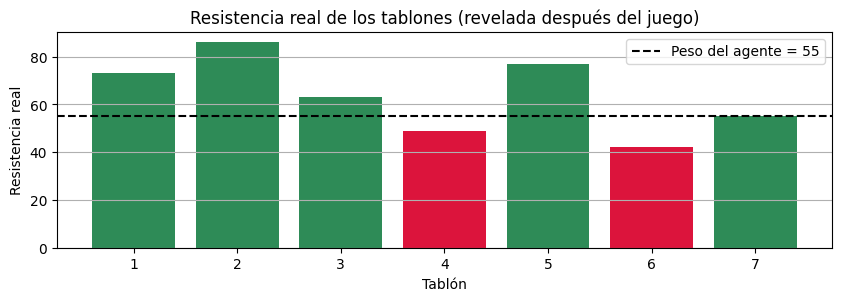

In [ ]:
colores = ["seagreen" if soporta else "crimson"
           for soporta in resultado["Soporta_Peso"]]

plt.figure(figsize=(10, 2.8))
plt.bar(resultado["Tablon"], resultado["Resistencia_Real"], color=colores)
plt.axhline(PESO_AGENTE, color="black", linestyle="--",
            label=f"Peso del agente = {PESO_AGENTE}")
plt.xticks(range(1, NUM_TABLONES + 1))
plt.xlabel("Tablón")
plt.ylabel("Resistencia real")
plt.title("Resistencia real de los tablones (revelada después del juego)")
plt.legend()
plt.grid(axis="y")
plt.show()